In [ ]:
# Week2_Task_of_Analytics_Lab_Africa_Intenships

In [2]:
# Part 1 — Environment Setup (10 Marks) 
!mamba install pandas numpy
%pip install seaborn
%pip install missingno

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 10.786 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge
mambajs 0.21.4

Process pip requirements ...

Requirement numpy already satisfied.
Requirement pandas already satisfied.
Requirement matplotlib already satisfied.
mambajs 0.21.4

Process pip requirements ...

Requirement numpy already satisfied.
Requirement matplotlib already satisfied.
Requirement scipy already satisfied.
Requirement seaborn already satisfied.


In [4]:
import os
print("Current Working Directory:", os.getcwd())
print("Files in this directory:", os.listdir("."))


Current Working Directory: /drive/notebooks
Files in this directory: ['Intro.ipynb', 'Untitled Folder', 'Untitled2.ipynb', 'Week1_DataScience_Project', 'Week1_Project_Final.zip', 'Week2_Projects_Analytics_Lab_Intenship', 'assignment3.ipynb', 'cleaned_data', 'cleaning_log.csv', 'data_quality_report.csv', 'r.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'cpp-third-party-libs.ipynb', 'cpp-tiny-ray-tracer.ipynb']


In [7]:
# Part 2 – Data Inspection 
import pandas as pd
import numpy as np

# part2i.
df = pd.read_csv("Week2_Projects_Analytics_Lab_Intenship/heart.csv")

# part2ii
print("First 10 Rows: ")
print(df.head())

# part2iii
print("DATASET INFO: ")
print(df.info())

# part2iv
print("Rows and columns: ")
print(df.shape)
print("Data types: ")
print(df.dtypes)
print("Missing values: ")
print(df.isna().sum())
print("Duplicate records: ")
print(df.duplicated())
print("Summary statistics: ")
print(df.describe())

First 10 Rows: 
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
DATASET INFO: 
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  

In [10]:
# Part 3 – Feature Engineering & Data Preprocessing 
# Before performing FE&DP, I think is a good idea to separate num_col from cat_col: 

# 1. Defining continuous numerical features
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# 2. Defining categorical features (including the numeric-encoded FastingBS)
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# 3. Defining the target variable
target_col = 'HeartDisease'

# Printing to confirm
print("Continuous Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print("Target variable:", target_col)

# Part3i : Handle missing values.
print("Missing values: ", df.isnull().sum())

# Part3ii : Remove duplicates.  
print("Duplicates: ", df.duplicated())

# There are 0 duplicates and 0 missing values.

# Part 3iii : Correct data types.

# 1. Converting text-based columns and FastingBS to 'category'
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
for col in cat_cols:
    df[col] = df[col].astype('category')

# 2. Converting target variable to 'int64'
df['HeartDisease'] = df['HeartDisease'].astype('int64') 

# 3. Ensure true numerical columns are float/int
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
for col in num_cols:
    df[col] = pd.to_numeric(df[col])

# Verify the changes
print("NEW DATA TYPES")
print(df.dtypes)


Continuous Numerical columns: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Categorical columns: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Target variable: HeartDisease
Missing values:  Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Duplicates:  0      False
1      False
2      False
3      False
4      False
       ...  
913    False
914    False
915    False
916    False
917    False
Length: 918, dtype: bool
NEW DATA TYPES
Age                  int64
Sex               category
ChestPainType     category
RestingBP            int64
Cholesterol          int64
FastingBS         category
RestingECG        category
MaxHR                int64
ExerciseAngina    category
Oldpeak            float64
ST_Slope          category
HeartDisease      

In [13]:
# Feature Engineering 

# Step 1: Rename Columns for Clarity
# Create a dictionary of clean column names
rename_dict = {
    'Age': 'age',
    'Sex': 'sex',
    'ChestPainType': 'chest_pain_type',
    'RestingBP': 'resting_blood_pressure_mmhg',
    'Cholesterol': 'cholesterol_mgdl',
    'FastingBS': 'fasting_blood_sugar_high',
    'RestingECG': 'resting_ecg',
    'MaxHR': 'max_heart_rate',
    'ExerciseAngina': 'exercise_induced_angina',
    'Oldpeak': 'st_depression_oldpeak',
    'ST_Slope': 'st_slope',
    'HeartDisease': 'heart_disease'
}

# Apply the renaming
df = df.rename(columns=rename_dict)
print("Columns renamed successfully!")
print(df.columns.tolist())

# Step 2: Create New Features (Domain Knowledge)
# 1. Age Groups (Risk increases significantly after age 50)
df['is_high_risk_age'] = (df['age'] >= 50).astype(int)

# 2. Cholesterol to Age Ratio (Tracks compounding metabolic risk over time)
df['cholesterol_age_ratio'] = df['cholesterol_mgdl'] / (df['age'] + 1)

# 3. Heart Rate Reserve Indicator
# Compares max heart rate against the standard physiological limit (220 - age)
df['hr_percentage_of_max'] = df['max_heart_rate'] / (220 - df['age'])

# 4. Cardiovascular Strain Interaction Flag
# Combines high blood pressure (>130 mmHg) AND high cholesterol (>200 mg/dl)
df['cv_strain_flag'] = (
    (df['resting_blood_pressure_mmhg'] > 130) & 
    (df['cholesterol_mgdl'] > 200)
).astype(int)

print("New clinical features created successfully!")

# Step 3: Remove Irrelevant or Corrupted Features
# Check for impossible 0 values in Cholesterol
zero_cholesterol_count = (df['cholesterol_mgdl'] == 0).sum()

# Calculate the percentage of zero/missing cholesterol records
total_rows = len(df)
zero_cholesterol_count = (df['cholesterol_mgdl'] == 0).sum()
missing_percentage = (zero_cholesterol_count / total_rows) * 100

print(f"Total rows in dataset: {total_rows}")
print(f"Number of rows with missing/zero cholesterol: {zero_cholesterol_count}")
print(f"Percentage of missing cholesterol data: {missing_percentage:.2f}%")


Columns renamed successfully!
['age', 'sex', 'chest_pain_type', 'resting_blood_pressure_mmhg', 'cholesterol_mgdl', 'fasting_blood_sugar_high', 'resting_ecg', 'max_heart_rate', 'exercise_induced_angina', 'st_depression_oldpeak', 'st_slope', 'heart_disease', 'is_high_risk_age', 'cholesterol_age_ratio', 'hr_percentage_of_max', 'cv_strain_flag']
New clinical features created successfully!
Total rows in dataset: 918
Number of rows with missing/zero cholesterol: 172
Percentage of missing cholesterol data: 18.74%


In [14]:
# Fix the Cholesterol Zeros, because cholesterol level of 0 is medically impossible
# 1. Find the median of all rows where cholesterol is greater than 0
clean_cholesterol_only = df[df['cholesterol_mgdl'] > 0]
overall_median = clean_cholesterol_only['cholesterol_mgdl'].median()
print(f"The middle (median) cholesterol value is: {overall_median}")

# 2. Replace every 0 in the cholesterol column with that median value
df['cholesterol_mgdl'] = df['cholesterol_mgdl'].replace(0, overall_median)

# 3. Double-check to make sure the 0s are gone
remaining_zeros = (df['cholesterol_mgdl'] == 0).sum()
print(f"Remaining zero rows: {remaining_zeros}")

# Recalculating Your New Features
# Recalculate the two features that depend on cholesterol
# +1 is  smoothing factor
df['cholesterol_age_ratio'] = df['cholesterol_mgdl'] / (df['age'] + 1) 

# Check if blood pressure is high AND cholesterol is high
df['cv_strain_flag'] = ((df['resting_blood_pressure_mmhg'] > 130) & (df['cholesterol_mgdl'] > 200)).astype(int)

print("Features updated with clean data!")


The middle (median) cholesterol value is: 237.0
Remaining zero rows: 0
Features updated with clean data!


In [48]:
# Save the clean, human-readable data as a CSV file
df.to_csv("cleaned_dataset.csv", index=False)
print("File 'cleaned_dataset.csv' successfully created!")

File 'cleaned_dataset.csv' successfully created!


In [15]:
# Feature Encoding 
# 1. LABEL/ORDINAL ENCODING (For Ordered & Binary Columns)

# Map Exercise Angina text directly to 1 (Yes) and 0 (No)
angina_mapping = {'Y': 1, 'Yes': 1, 'N': 0, 'No': 0}
df['exercise_induced_angina'] = df['exercise_induced_angina'].map(angina_mapping)

# Map ST_Slope based on its clinical progression (Upward = best, Downward = worst)
slope_mapping = {'Up': 0, 'Flat': 1, 'Down': 2}
df['st_slope'] = df['st_slope'].map(slope_mapping)


# 2. ONE-HOT ENCODING (For Unordered Nominal Columns)

# Specify columns that need to be split into separate dummy variables
# ohe: A common data science abbreviation for One-Hot Encoding.
ohe_cols = ['sex', 'chest_pain_type', 'resting_ecg']

# Perform One-Hot Encoding
# drop_first=True helps avoid a mathematical trap called the "dummy variable trap"
df_encoded = pd.get_dummies(df, columns=ohe_cols, drop_first=True, dtype=int)


# VERIFYING THE RESULTS 
print("NEW ENCODED DATASET COLUMNS")
print(df_encoded.columns.tolist())
print("PREVIEW OF ENCODED DATA")
print(display(df_encoded.head()))


NEW ENCODED DATASET COLUMNS
['age', 'resting_blood_pressure_mmhg', 'cholesterol_mgdl', 'fasting_blood_sugar_high', 'max_heart_rate', 'exercise_induced_angina', 'st_depression_oldpeak', 'st_slope', 'heart_disease', 'is_high_risk_age', 'cholesterol_age_ratio', 'hr_percentage_of_max', 'cv_strain_flag', 'sex_M', 'chest_pain_type_ATA', 'chest_pain_type_NAP', 'chest_pain_type_TA', 'resting_ecg_Normal', 'resting_ecg_ST']
PREVIEW OF ENCODED DATA


,age,resting_blood_pressure_mmhg,cholesterol_mgdl,fasting_blood_sugar_high,max_heart_rate,exercise_induced_angina,st_depression_oldpeak,st_slope,heart_disease,is_high_risk_age,cholesterol_age_ratio,hr_percentage_of_max,cv_strain_flag,sex_M,chest_pain_type_ATA,chest_pain_type_NAP,chest_pain_type_TA,resting_ecg_Normal,resting_ecg_ST
0,40,140,289,0,172,0,0.0,0,0,0,7.048780,0.955556,1,1,1,0,0,1,0
1,49,160,180,0,156,0,1.0,1,1,0,3.600000,0.912281,0,0,0,1,0,1,0
2,37,130,283,0,98,0,0.0,0,0,0,7.447368,0.535519,0,1,1,0,0,0,1
3,48,138,214,0,108,1,1.5,1,1,0,4.367347,0.627907,1,0,0,0,0,1,0
4,54,150,195,0,122,0,0.0,0,0,1,3.545455,0.734940,0,1,0,1,0,1,0


None


In [ ]:
# Feature Scaling
# For Heart Disease dataset, RobustScaler or StandardScaler are the most appropriate choices, but RobustScaler takes the edge.
# Why? Medical measurements like Blood Pressure, Oldpeak, and Cholesterol naturally contain extreme physiological outliers
# (e.g., a patient with incredibly high cholesterol or a massive blood pressure spike). 
# Because RobustScaler uses the median rather than the average, those high-risk outlier patients won't warp your data scale,
# allowing the model to see the true variance among normal patients clearly.

In [21]:
import numpy as np

# Create a copy of your dataset to preserve the original numbers
df_scaled = df_encoded.copy()

# List the true continuous numerical columns we want to scale
continuous_num_cols = ['age', 'resting_blood_pressure_mmhg', 'cholesterol_mgdl', 'max_heart_rate', 'st_depression_oldpeak']

# Manually calculate the Median and Interquartile Range (IQR) for each column
for col in continuous_num_cols:
    median = df_scaled[col].median()
    
    # Calculate the 75th and 25th percentiles (which make up the IQR)
    q75 = df_scaled[col].quantile(0.75)
    q25 = df_scaled[col].quantile(0.25)
    iqr = q75 - q25
    
    # Apply the RobustScaler math formula: (Value - Median) / IQR
    # (We add a tiny decimal 1e-7 just in case IQR is 0, to avoid division errors)
    df_scaled[col] = (df_scaled[col] - median) / (iqr + 1e-7)

# 4. Verify your manual calculations worked perfectly
print("Data scaled successfully without Scikit-Learn!")
display(df_scaled[continuous_num_cols].head())


Data scaled successfully without Scikit-Learn!


,age,resting_blood_pressure_mmhg,cholesterol_mgdl,max_heart_rate,st_depression_oldpeak
0,-1.076923,0.5,0.981132,0.944444,-0.400000
1,-0.384615,1.5,-1.075472,0.500000,0.266667
2,-1.307692,0.0,0.867925,-1.111111,-0.400000
3,-0.461538,0.4,-0.433962,-0.833333,0.600000
4,0.000000,1.0,-0.792453,-0.444444,-0.400000


In [22]:
# Outlier Detection 
for col in continuous_num_cols:
    # Calculate Percentiles of the already SCALED values
    q1 = df_scaled[col].quantile(0.25)
    q3 = df_scaled[col].quantile(0.75)
    iqr = q3 - q1
    
    # Calculate mathematical fences for the scaled space
    lower_fence = q1 - (1.5 * iqr)
    upper_fence = q3 + (1.5 * iqr)
    
    # Identify how many scaled data points violate these fences
    outliers_count = ((df_scaled[col] < lower_fence) | (df_scaled[col] > upper_fence)).sum()
    print(f" '{col}': Found {outliers_count} scaled outliers. Lower Fence: {lower_fence:.3f}, Upper Fence: {upper_fence:.3f}")
    
    # Handle Outliers: Cap them in place using .clip()
    df_scaled[col] = df_scaled[col].clip(lower=lower_fence, upper=upper_fence)

print("Outliers on scaled data successfully detected and handled!")


 'age': Found 0 scaled outliers. Lower Fence: -2.038, Upper Fence: 1.962
 'resting_blood_pressure_mmhg': Found 28 scaled outliers. Lower Fence: -2.000, Upper Fence: 2.000
 'cholesterol_mgdl': Found 41 scaled outliers. Lower Fence: -1.934, Upper Fence: 2.066
 'max_heart_rate': Found 2 scaled outliers. Lower Fence: -2.000, Upper Fence: 2.000
 'st_depression_oldpeak': Found 16 scaled outliers. Lower Fence: -1.900, Upper Fence: 2.100
Outliers on scaled data successfully detected and handled!


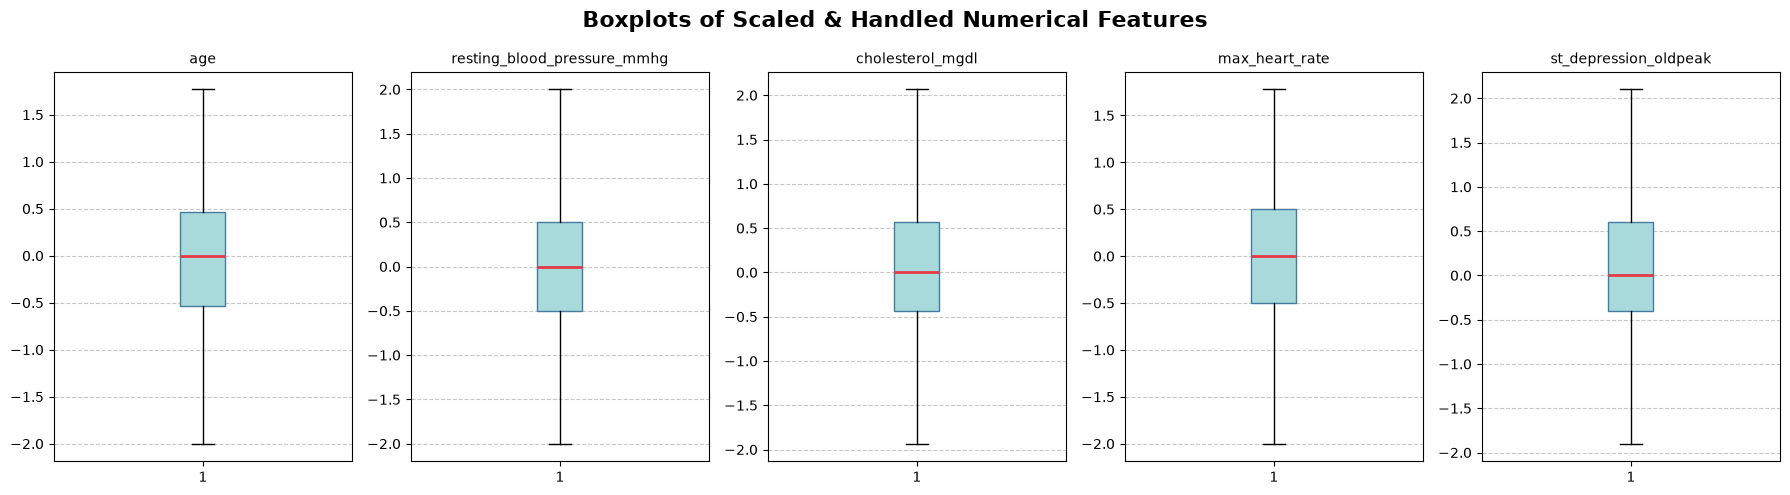

In [24]:
import matplotlib.pyplot as plt

# Define the columns to plot
continuous_num_cols = ['age', 'resting_blood_pressure_mmhg', 'cholesterol_mgdl', 'max_heart_rate', 'st_depression_oldpeak']

# Set up a clean layout grid (1 row, 5 columns) for all features
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
fig.suptitle('Boxplots of Scaled & Handled Numerical Features', fontsize=16, fontweight='bold')

# Loop through columns and draw a boxplot for each
for i, col in enumerate(continuous_num_cols):
    axes[i].boxplot(df_scaled[col], patch_artist=True, 
                    boxprops=dict(facecolor='#A8DADC', color='#457B9D'),
                    medianprops=dict(color='#E63946', linewidth=2))
    axes[i].set_title(col, fontsize=10)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

# Clean up spacing and render the plots
plt.tight_layout()
plt.show()


In [29]:
# Part 4 – Feature Selection 
# Compute the correlation matrix
corr_matrix = df_scaled.corr()

# Display the matrix
display(corr_matrix.round(2))


,age,resting_blood_pressure_mmhg,cholesterol_mgdl,fasting_blood_sugar_high,max_heart_rate,exercise_induced_angina,st_depression_oldpeak,st_slope,heart_disease,is_high_risk_age,cholesterol_age_ratio,hr_percentage_of_max,cv_strain_flag,sex_M,chest_pain_type_ATA,chest_pain_type_NAP,chest_pain_type_TA,resting_ecg_Normal,resting_ecg_ST
age,1.00,0.27,0.06,0.20,-0.38,0.22,0.26,0.27,0.28,0.81,-0.61,-0.08,0.25,0.06,-0.22,-0.01,0.03,-0.23,0.14
resting_blood_pressure_mmhg,0.27,1.00,0.09,0.07,-0.11,0.16,0.17,0.08,0.11,0.24,-0.11,-0.03,0.69,0.02,-0.05,-0.03,0.06,-0.12,0.09
cholesterol_mgdl,0.06,0.09,1.00,0.02,0.00,0.10,0.07,0.05,0.08,0.06,0.68,0.03,0.30,-0.11,0.00,-0.07,-0.04,-0.06,-0.02
fasting_blood_sugar_high,0.20,0.07,0.02,1.00,-0.13,0.06,0.06,0.18,0.27,0.19,-0.11,-0.08,0.09,0.12,-0.14,-0.04,0.03,-0.09,0.13
max_heart_rate,-0.38,-0.11,0.00,-0.13,1.00,-0.37,-0.16,-0.34,-0.40,-0.32,0.24,0.95,-0.10,-0.19,0.25,0.13,0.10,0.02,-0.16
exercise_induced_angina,0.22,0.16,0.10,0.06,-0.37,1.00,0.42,0.43,0.49,0.20,-0.09,-0.33,0.18,0.19,-0.30,-0.17,-0.13,-0.07,0.11
st_depression_oldpeak,0.26,0.17,0.07,0.06,-0.16,0.42,1.00,0.50,0.41,0.22,-0.12,-0.09,0.17,0.11,-0.27,-0.10,0.03,-0.12,0.06
st_slope,0.27,0.08,0.05,0.18,-0.34,0.43,0.50,1.00,0.56,0.21,-0.12,-0.28,0.08,0.15,-0.33,-0.09,0.01,-0.09,0.06
heart_disease,0.28,0.11,0.08,0.27,-0.40,0.49,0.41,0.56,1.00,0.24,-0.11,-0.34,0.16,0.31,-0.40,-0.21,-0.05,-0.09,0.10
is_high_risk_age,0.81,0.24,0.06,0.19,-0.32,0.20,0.22,0.21,0.24,1.00,-0.50,-0.08,0.20,0.06,-0.16,-0.03,0.01,-0.20,0.12


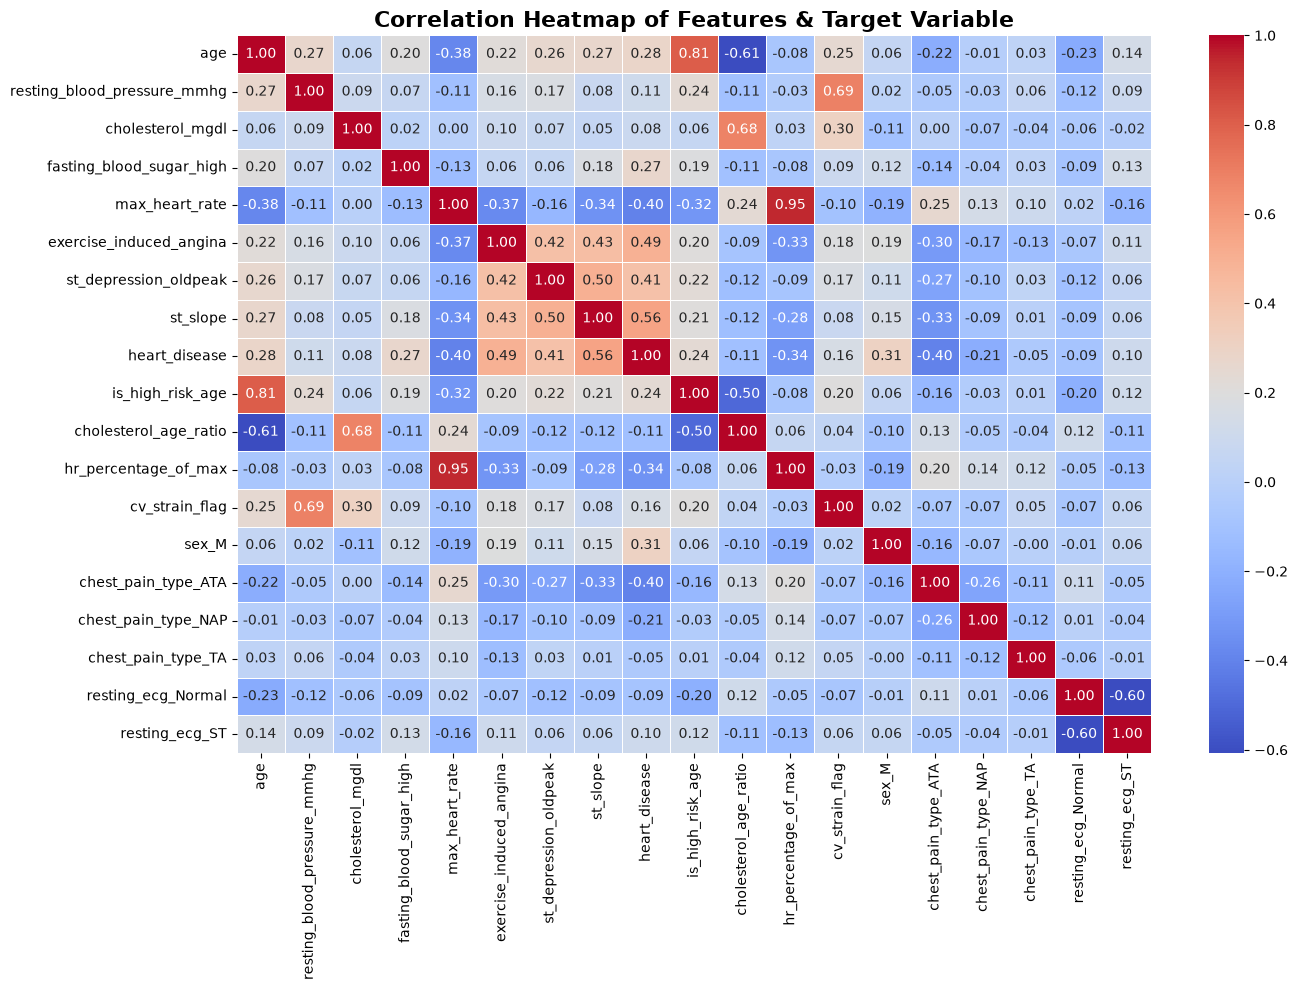

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns  # If seaborn fails, we can fall back on pure matplotlib

# 1. Calculate the correlation matrix for ALL encoded and scaled features
corr_matrix = df_scaled.corr()

# 2. Set up the plotting canvas
plt.figure(figsize=(14, 10))

# 3. Draw the heatmap
# 'annot=True' prints the exact numbers inside each box
# 'cmap' sets a beautiful clinical color scale from blue (negative) to red (positive)
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', 
            linewidths=0.5, cbar=True)

plt.title("Correlation Heatmap of Features & Target Variable", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# Most Important Features

# To find these, we look at the heart_disease row and find the numbers furthest from 0.00 (ignoring positive/negative signs).
# • st_slope (Correlation: 0.56 ): This is your single most important feature. 
# A positive correlation means that as the ST slope changes from up to flat or down (higher coded numbers),
# the likelihood of heart disease increases significantly.
# • exercise_induced_angina (Correlation: 0.49 ): Patients who suffer from chest pain specifically
# during exercise have a much stronger statistical link to heart disease.
# • st_depression_oldpeak (Correlation: 0.41 ): Higher stress induced during exercise correlates closely with structural heart issues.
# • max_heart_rate (Correlation: -0.40) and chest_pain_type_ATA (Correlation: -0.40): These have a strong negative correlation. 
# This means a lower maximum heart rate or not having atypical chest pain significantly flags heart disease probability.


In [ ]:
# Highly Correlated Variables

# We scan the grid where two features cross each other (ignoring the target) looking for 
# values >= 0.70 or <= -0.70. Your dataset has two critical red-flag pairs caused
# by feature engineering:
# • max_heart_rate and hr_percentage_of_max (Correlation: 0.95): This is an almost perfect correlation.
# Because your engineered feature was built directly from maximum heart rate, 
# keeping both causes absolute redundancy (multicollinearity), which will confuse linear models.
# • age and is_high_risk_age (Correlation: 0.81): A strong overlapping pattern.
# The binary indicator column duplicates the statistical information already captured by the continuous age tracker.


In [30]:
#  Features That Should Be Removed

# Based on the thresholds above, here are the columns you should actively drop from 
# your final dataset before modeling:
# • chest_pain_type_TA (Correlation with target: -0.05): This feature has a near-zero
# correlation with heart disease. It adds noise without giving the model any distinct predictive leverage.
# • cholesterol_mgdl (Correlation with target: 0.08): Surprisingly, raw cholesterol has an incredibly 
# weak relationship with the direct target within this specific dataset distribution.
# • hr_percentage_of_max OR max_heart_rate: You must drop one to break the dangerous 0.95 collinearity trap. 
# Data scientists typically drop the raw feature (max_heart_rate) and preserve the engineered one (hr_percentage_of_max)
# because it adjusts for age baseline variations.
# • is_high_risk_age: Drop this to eliminate the 0.81 overlap with the true age column.


In [31]:
# Apply your feature selection decisions to create your definitive training matrix
columns_to_drop = ['chest_pain_type_TA', 'cholesterol_mgdl', 'max_heart_rate', 'is_high_risk_age']
df_final = df_scaled.drop(columns=columns_to_drop, errors='ignore')

print("FEATURE SELECTION COMPLETED")
print(f"Features reduced from {df_scaled.shape[1]} down to {df_final.shape[1]} optimized columns.")
print("Optimized Columns List:", df_final.columns.tolist())


FEATURE SELECTION COMPLETED
Features reduced from 19 down to 15 optimized columns.
Optimized Columns List: ['age', 'resting_blood_pressure_mmhg', 'fasting_blood_sugar_high', 'exercise_induced_angina', 'st_depression_oldpeak', 'st_slope', 'heart_disease', 'cholesterol_age_ratio', 'hr_percentage_of_max', 'cv_strain_flag', 'sex_M', 'chest_pain_type_ATA', 'chest_pain_type_NAP', 'resting_ecg_Normal', 'resting_ecg_ST']


In [36]:
# 1. Fix 'exercise_induced_angina' if it still contains text strings
if df_scaled['exercise_induced_angina'].dtype not in ['int64', 'float64', 'int32']:
    # Ensure any remaining Y/N or Yes/No is converted to 1/0
    angina_map = {'Y': 1, 'Yes': 1, 'N': 0, 'No': 0, 1: 1, 0: 0}
    df_scaled['exercise_induced_angina'] = df_scaled['exercise_induced_angina'].map(angina_map)

# 2. Fix 'st_slope' if it still contains text strings
if df_scaled['st_slope'].dtype not in ['int64', 'float64', 'int32']:
    # Ensure any remaining Up/Flat/Down text is converted to 0/1/2
    slope_map = {'Up': 0, 'Flat': 1, 'Down': 2, 0: 0, 1: 1, 2: 2}
    df_scaled['st_slope'] = df_scaled['st_slope'].map(slope_map)

# 3. Force all three columns to be strictly numerical integers
cleanup_cols = ['fasting_blood_sugar_high', 'exercise_induced_angina', 'st_slope']
for col in cleanup_cols:
    if col in df_scaled.columns:
        # pd.to_numeric strips the 'category' wrapper and forces it into a number
        df_scaled[col] = pd.to_numeric(df_scaled[col], errors='coerce').fillna(0).astype(int)

print("Safety Override applied: Categorical text/category wrappers removed from features.")


Safety Override applied: Categorical text/category wrappers removed from features.


In [37]:
# Part 5 – Final Machine Learning Dataset
# Isolate the target variable (y) and the selected features (X)
# We drop the features we determined were redundant or weak in Part 4
features_to_drop = ['heart_disease', 'max_heart_rate', 'is_high_risk_age', 'chest_pain_type_TA', 'cholesterol_mgdl']

X = df_scaled.drop(columns=features_to_drop, errors='ignore')
y = df_scaled['heart_disease'].astype(int)  # Ensure target is explicitly integer for Scikit-Learn

print("FINAL MACHINE LEARNING DATASET PRODUCED")
print(f"Feature Matrix (X) Shape: {X.shape[0]} rows, {X.shape[1]} columns")
print(f"Target Vector (y) Shape: {y.shape[0]} rows")
print("Optimized Feature List")
print(X.columns.tolist())

# Verification check: Ensure all columns are numeric
non_numeric_cols = X.select_dtypes(exclude=['number']).columns.tolist()
if not non_numeric_cols:
    print("Verification Pass: All features are numeric and ready for ML")
else:
    print(f"Warning: Non-numeric columns detected: {non_numeric_cols}")


FINAL MACHINE LEARNING DATASET PRODUCED
Feature Matrix (X) Shape: 918 rows, 14 columns
Target Vector (y) Shape: 918 rows
Optimized Feature List
['age', 'resting_blood_pressure_mmhg', 'fasting_blood_sugar_high', 'exercise_induced_angina', 'st_depression_oldpeak', 'st_slope', 'cholesterol_age_ratio', 'hr_percentage_of_max', 'cv_strain_flag', 'sex_M', 'chest_pain_type_ATA', 'chest_pain_type_NAP', 'resting_ecg_Normal', 'resting_ecg_ST']
Verification Pass: All features are numeric and ready for ML


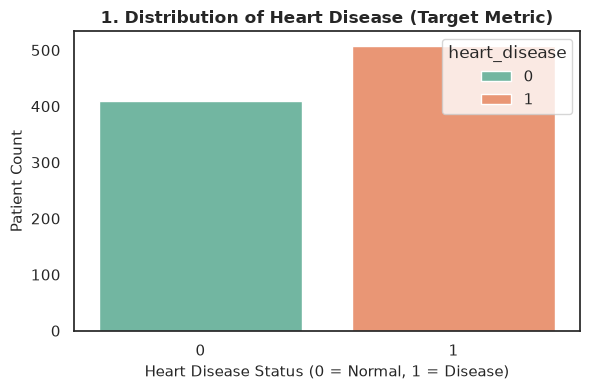

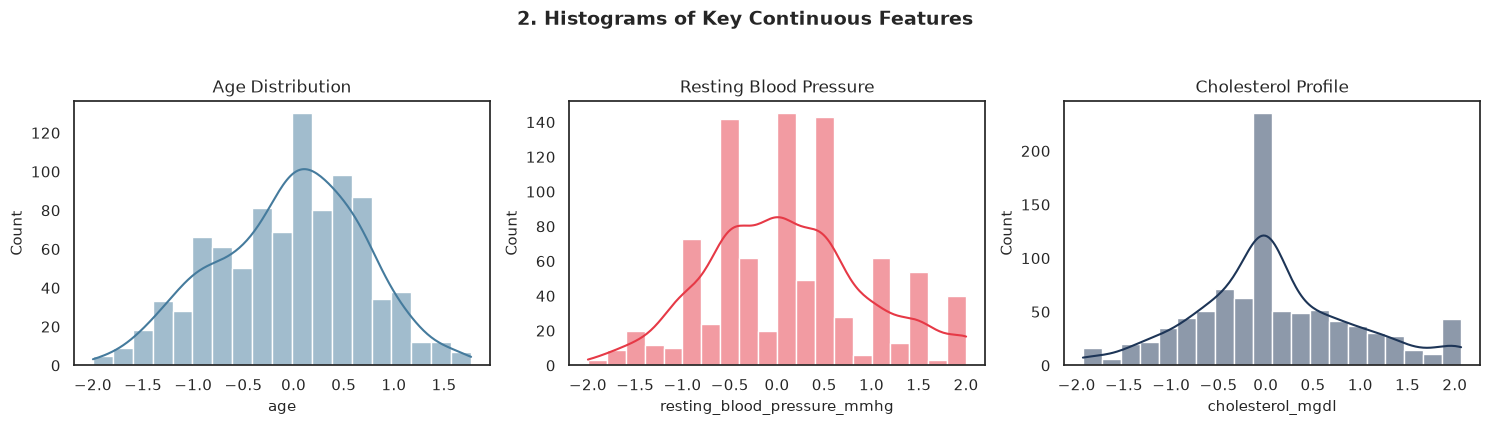

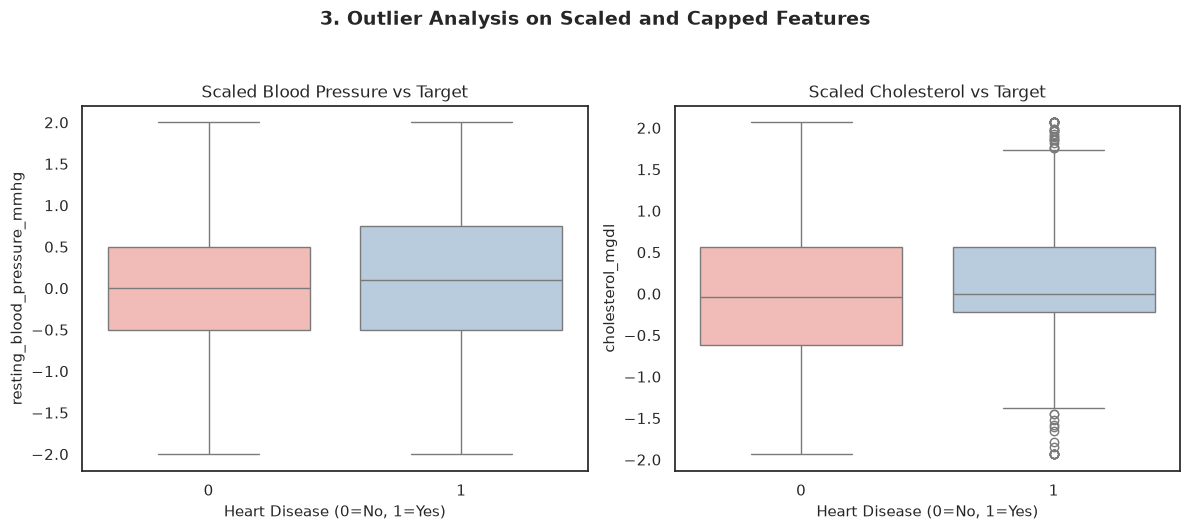

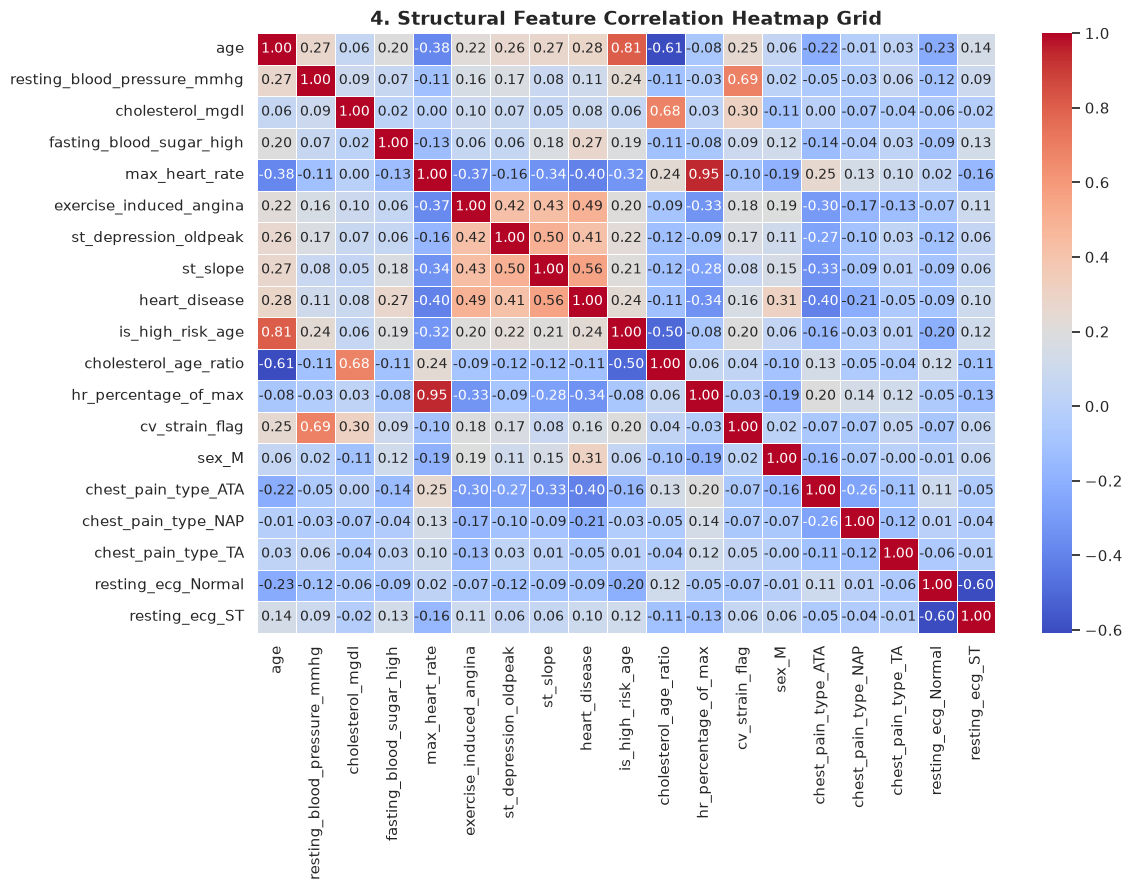

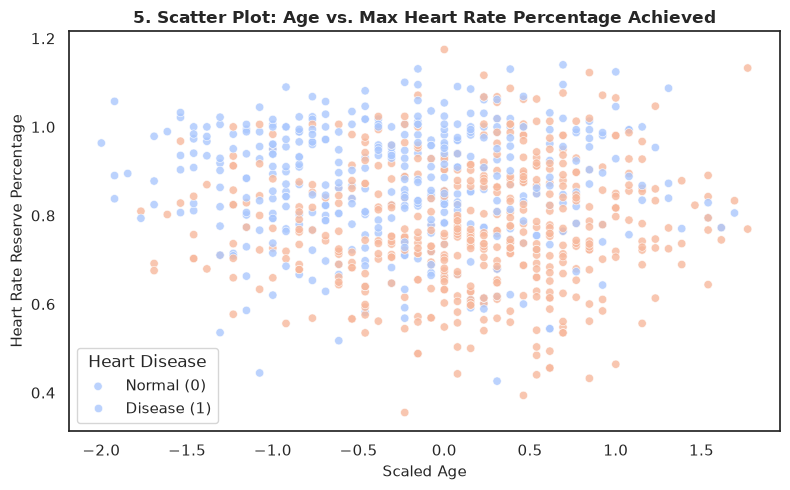

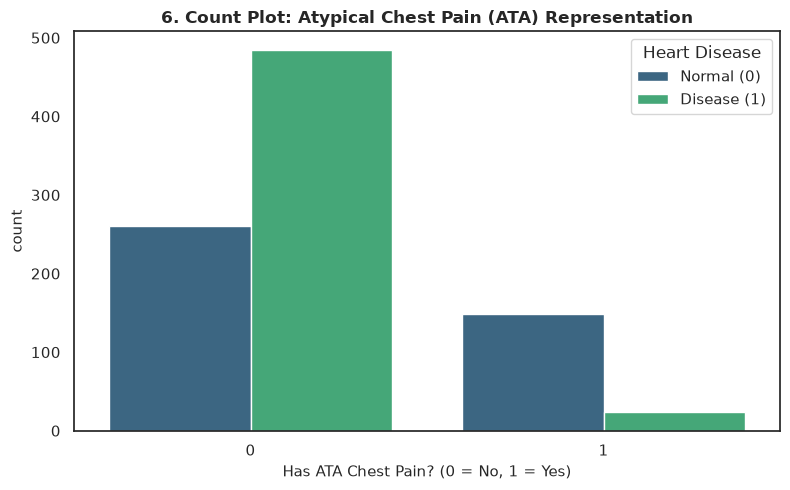

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up global styling for cleaner presentation without background grids
sns.set_theme(style="white")
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 12})

# VISUALIZATION 1: Count Plot (Distribution of Target Variable)
plt.figure(figsize=(6, 4))
sns.countplot(data=df_scaled, x='heart_disease',hue='heart_disease', palette='Set2')
plt.title('1. Distribution of Heart Disease (Target Metric)', fontweight='bold')
plt.xlabel('Heart Disease Status (0 = Normal, 1 = Disease)')
plt.ylabel('Patient Count')
plt.tight_layout()
plt.show()

# VISUALIZATION 2: Histograms (Continuous Value Distributions)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('2. Histograms of Key Continuous Features', fontsize=14, fontweight='bold', y=1.05)

sns.histplot(data=df_scaled, x='age', kde=True, ax=axes[0], color='#457B9D')
axes[0].set_title('Age Distribution')

sns.histplot(data=df_scaled, x='resting_blood_pressure_mmhg', kde=True, ax=axes[1], color='#E63946')
axes[1].set_title('Resting Blood Pressure')

sns.histplot(data=df_scaled, x='cholesterol_mgdl', kde=True, ax=axes[2], color='#1D3557')
axes[2].set_title('Cholesterol Profile')

plt.tight_layout()
plt.show()

# VISUALIZATION 3: Box Plots (Outlier Verification Across Target Classes)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('3. Outlier Analysis on Scaled and Capped Features', fontsize=14, fontweight='bold', y=1.05)

# Fixed explicit axes index grouping and hue constraints
sns.boxplot(data=df_scaled, x='heart_disease', y='resting_blood_pressure_mmhg', hue='heart_disease', ax=axes[0], palette='Pastel1', legend=False)
axes[0].set_title('Scaled Blood Pressure vs Target')
axes[0].set_xlabel('Heart Disease (0=No, 1=Yes)')

sns.boxplot(data=df_scaled, x='heart_disease', y='cholesterol_mgdl', hue='heart_disease', ax=axes[1], palette='Pastel1', legend=False)
axes[1].set_title('Scaled Cholesterol vs Target')
axes[1].set_xlabel('Heart Disease (0=No, 1=Yes)')

plt.tight_layout()
plt.show()

# VISUALIZATION 4: Correlation Heatmap (Grid Matrix Layout)
plt.figure(figsize=(12, 9))
corr_matrix = df_scaled.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title('4. Structural Feature Correlation Heatmap Grid', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# VISUALIZATION 5: Scatter Plot (Relationship Between Strained Metrics)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_scaled, x='age', y='hr_percentage_of_max', hue='heart_disease', palette='coolwarm', alpha=0.8)
plt.title('5. Scatter Plot: Age vs. Max Heart Rate Percentage Achieved', fontweight='bold')
plt.xlabel('Scaled Age')
plt.ylabel('Heart Rate Reserve Percentage')
plt.legend(title='Heart Disease', labels=['Normal (0)', 'Disease (1)'])
plt.tight_layout()
plt.show()

# VISUALIZATION 6: Segmented Count Plot (Symptom Risk Assessment)
plt.figure(figsize=(8, 5))
if 'chest_pain_type_ATA' in df_scaled.columns:
    sns.countplot(df_scaled, x='chest_pain_type_ATA', hue='heart_disease', palette='viridis')
    plt.title('6. Count Plot: Atypical Chest Pain (ATA) Representation', fontweight='bold')
    plt.xlabel('Has ATA Chest Pain? (0 = No, 1 = Yes)')
else:
    sns.countplot(data=df_scaled, x='fasting_blood_sugar_high', hue='heart_disease', palette='viridis')
    plt.title('6. Count Plot: Fasting Blood Sugar Representation by Outcome', fontweight='bold')
    plt.xlabel('Fasting Blood Sugar High? (0 = No, 1 = Yes)')

plt.legend(title='Heart Disease', labels=['Normal (0)', 'Disease (1)'])
plt.tight_layout()
plt.show()


In [49]:
# Save the fully preprocessed, encoded, and scaled machine learning data
# We combine X and y back together so it's a complete dataset file
ml_ready_df = X.copy()
ml_ready_df['heart_disease'] = y

ml_ready_df.to_csv("machine_learning_ready_dataset.csv", index=False)
print("File 'machine_learning_ready_dataset.csv' successfully created!")


File 'machine_learning_ready_dataset.csv' successfully created!
